# How stocks move

Eight fictional stocks start at the same price. Their individual paths diverge before a shared driver grows stronger. Each synthetic trading session is one observation.

This is a seeded teaching example. Dates are illustrative.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from panic_detector.features.returns import daily_log_returns

rng = np.random.default_rng(2020)
dates = pd.bdate_range("2019-01-02", periods=320)
common = rng.normal(size=(320, 1))
strength = np.where(np.arange(320)[:, None] < 200, 0.18, 1.6)
moves = 0.009 * (rng.normal(size=(320, 8)) + strength * common)
prices = pd.DataFrame(100 * np.exp(moves.cumsum(axis=0)), index=dates, columns=list("ABCDEFGH"))
returns = daily_log_returns(prices)

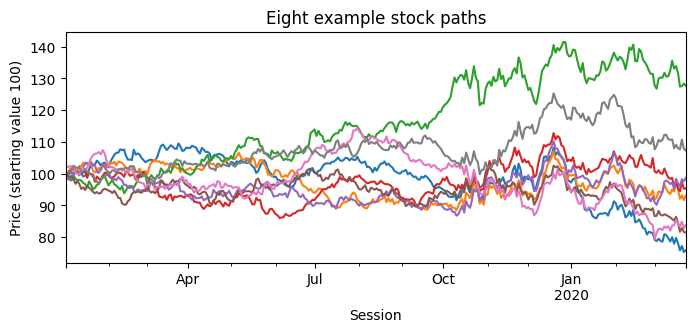

,A,B,C,D,E,F,G,H
count,319.0000,319.0000,319.0000,319.0000,319.0000,319.0000,319.0000,319.0000
mean,-0.0009,-0.0002,0.0008,-0.0001,-0.0001,-0.0006,-0.0006,0.0002
std,0.0129,0.0129,0.0133,0.0125,0.0129,0.0120,0.0125,0.0121
min,-0.0450,-0.0449,-0.0606,-0.0414,-0.0437,-0.0335,-0.0550,-0.0391
25%,-0.0078,-0.0075,-0.0077,-0.0073,-0.0090,-0.0069,-0.0082,-0.0069
50%,-0.0010,-0.0005,0.0003,-0.0007,-0.0004,-0.0017,0.0003,-0.0002
75%,0.0066,0.0078,0.0090,0.0077,0.0076,0.0067,0.0071,0.0070
max,0.0367,0.0470,0.0377,0.0371,0.0505,0.0386,0.0365,0.0478


In [2]:
fig, ax = plt.subplots(figsize=(8, 3))
prices.plot(ax=ax, legend=False)
ax.set(ylabel="Price (starting value 100)", xlabel="Session", title="Eight example stock paths")
display(fig); plt.close(fig)
display(returns.describe().round(4))